In [9]:
import os
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px
import numpy as np

In [10]:
# Load World Happiness data (2017)
happiness_df = pd.read_csv("../../data/raw/2017.csv")

# Structural overview
print(f"Dataset shape: {happiness_df.shape}")
print("-" * 50)
happiness_df.info()

Dataset shape: (155, 12)
--------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 155 entries, 0 to 154
Data columns (total 12 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Country                        155 non-null    object 
 1   Happiness.Rank                 155 non-null    int64  
 2   Happiness.Score                155 non-null    float64
 3   Whisker.high                   155 non-null    float64
 4   Whisker.low                    155 non-null    float64
 5   Economy..GDP.per.Capita.       155 non-null    float64
 6   Family                         155 non-null    float64
 7   Health..Life.Expectancy.       155 non-null    float64
 8   Freedom                        155 non-null    float64
 9   Generosity                     155 non-null    float64
 10  Trust..Government.Corruption.  155 non-null    float64
 11  Dystopia.Residual              155

In [11]:
happiness_df.isnull().sum()

Country                          0
Happiness.Rank                   0
Happiness.Score                  0
Whisker.high                     0
Whisker.low                      0
Economy..GDP.per.Capita.         0
Family                           0
Health..Life.Expectancy.         0
Freedom                          0
Generosity                       0
Trust..Government.Corruption.    0
Dystopia.Residual                0
dtype: int64

In [12]:
duplicated_values = happiness_df.duplicated()
duplicated_values.sum()

np.int64(0)

In [13]:
display(happiness_df.select_dtypes(include='number').describe().T)

,count,mean,std,min,25%,50%,75%,max
Happiness.Rank,155.0,78.000000,44.888751,1.000000,39.500000,78.000000,116.500000,155.000000
Happiness.Score,155.0,5.354019,1.131230,2.693000,4.505500,5.279000,6.101500,7.537000
Whisker.high,155.0,5.452326,1.118542,2.864884,4.608172,5.370032,6.194600,7.622030
Whisker.low,155.0,5.255713,1.145030,2.521116,4.374955,5.193152,6.006527,7.479556
Economy..GDP.per.Capita.,155.0,0.984718,0.420793,0.000000,0.663371,1.064578,1.318027,1.870766
Family,155.0,1.188898,0.287263,0.000000,1.042635,1.253918,1.414316,1.610574
Health..Life.Expectancy.,155.0,0.551341,0.237073,0.000000,0.369866,0.606042,0.723008,0.949492
Freedom,155.0,0.408786,0.149997,0.000000,0.303677,0.437454,0.516561,0.658249
Generosity,155.0,0.246883,0.134780,0.000000,0.154106,0.231538,0.323762,0.838075
Trust..Government.Corruption.,155.0,0.123120,0.101661,0.000000,0.057271,0.089848,0.153296,0.464308


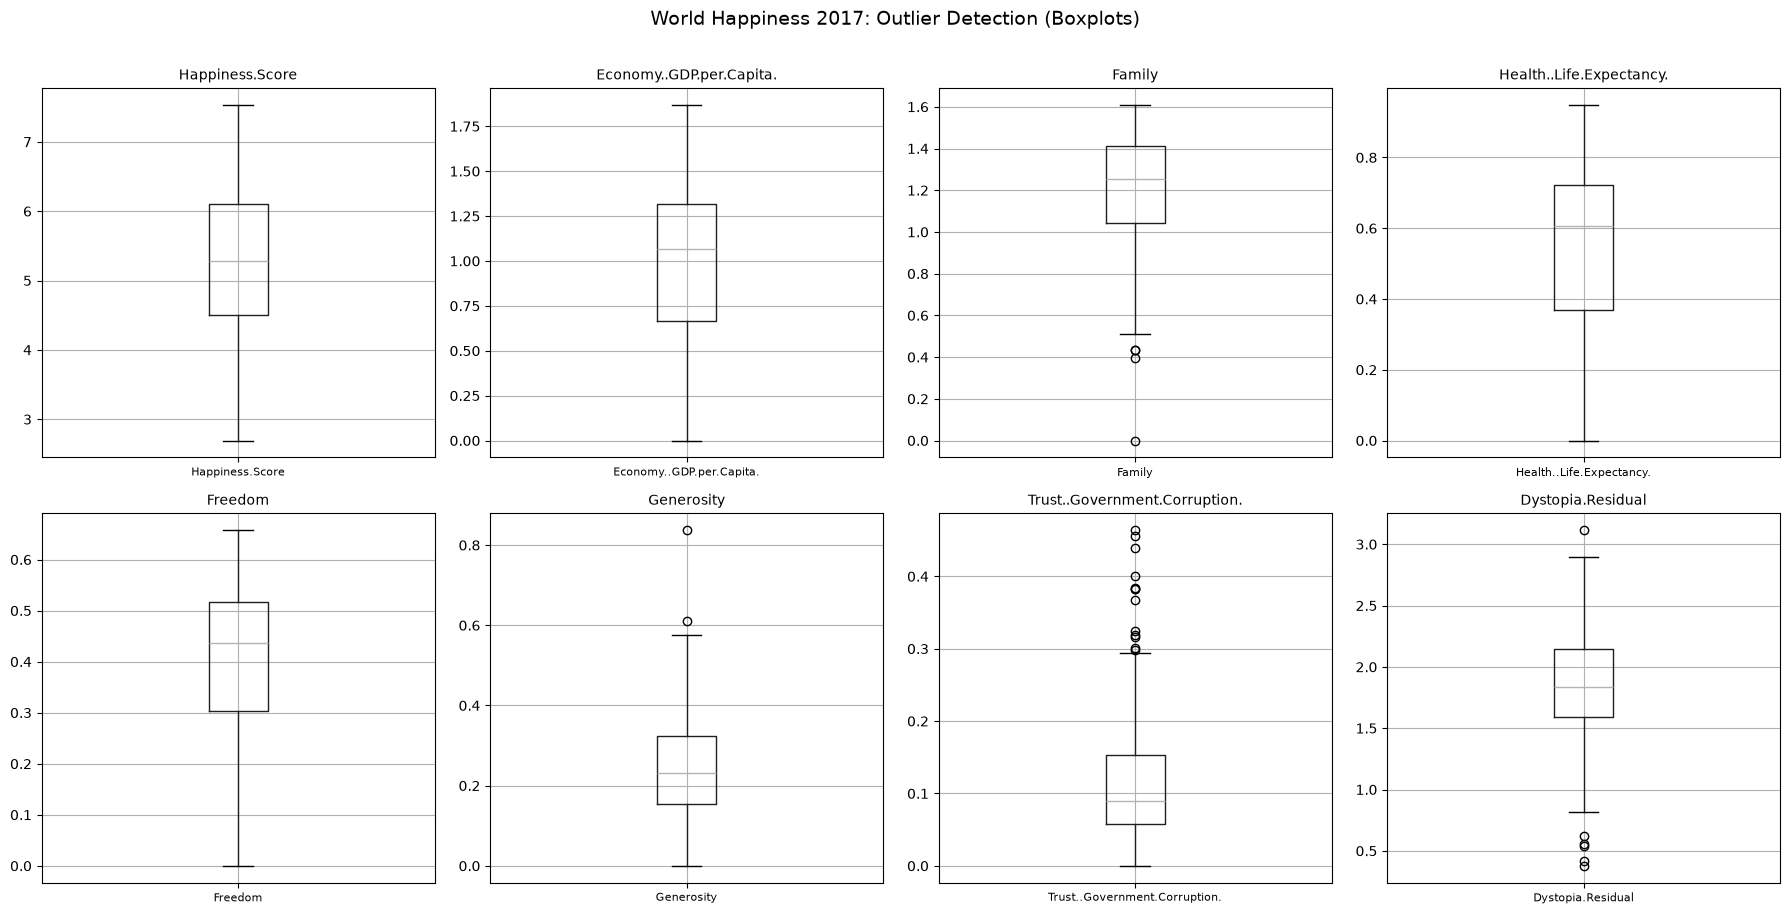

In [15]:

# Auto-detect all numeric columns
numeric_cols = happiness_df.select_dtypes(include=['number']).columns.tolist()

# 🛑 Drop useless columns for 2017 (Whiskers, Rank, etc.)
cols_to_drop = [
    'Happiness.Rank', 'Happiness Rank', 
    'Whisker.high', 'Whisker.low',
    'Lower Confidence Interval', 'Upper Confidence Interval',
    'Lower confidence interval', 'Upper confidence interval',
    'Year'
]
numeric_cols = [c for c in numeric_cols if c not in cols_to_drop]

# Calculate grid size
n = len(numeric_cols)
ncols = 4
nrows = math.ceil(n / ncols)

# Create the figure and axes grid
fig, axes = plt.subplots(nrows, ncols, figsize=(18, 4.5 * nrows))
axes = axes.flatten()

# Plot a boxplot for each numeric column
for i, col in enumerate(numeric_cols):
    happiness_df.boxplot(column=col, ax=axes[i], vert=True)
    axes[i].set_title(col, fontsize=10)
    axes[i].tick_params(axis="x", labelsize=8)

# Hide ONLY the unused axes
for ax in axes[n:]:
    ax.set_visible(False)

fig.suptitle("World Happiness 2017: Outlier Detection (Boxplots)", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

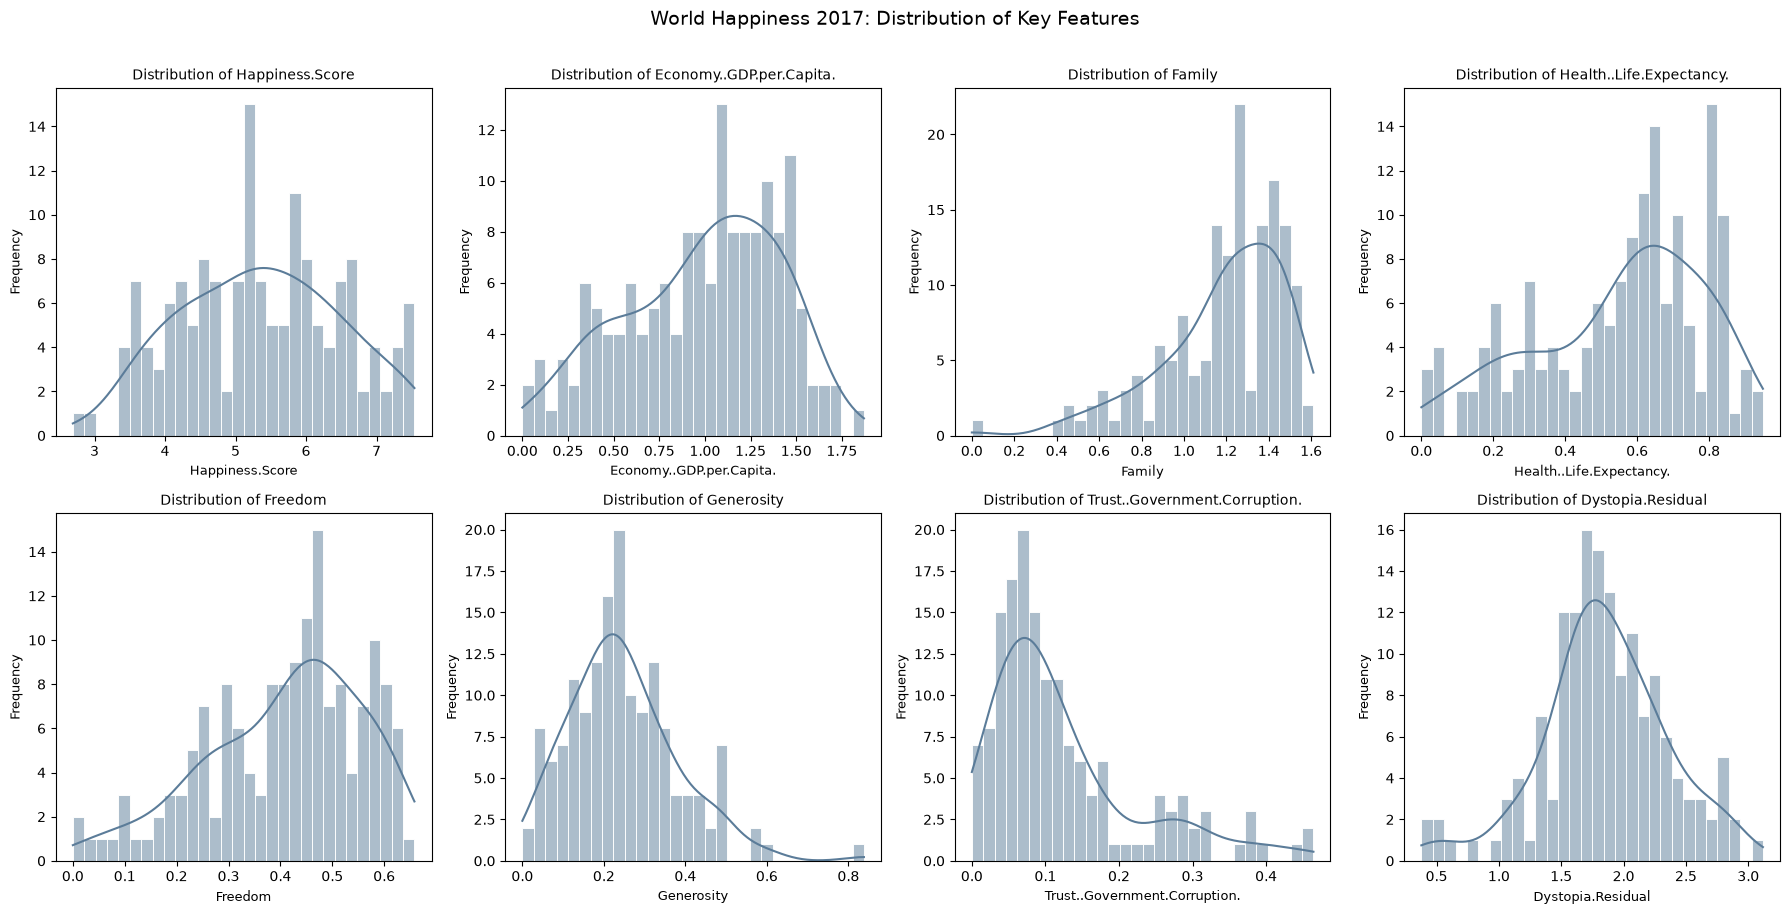

In [14]:

# 1. Auto-detect numeric columns
numeric_cols = happiness_df.select_dtypes(include=['number']).columns.tolist()

# 2. Drop useless columns specific to 2017 (Whiskers and Rank)
cols_to_exclude = [
    'Happiness.Rank', 'Happiness Rank', 
    'Whisker.high', 'Whisker.low',
    'Lower Confidence Interval', 'Upper Confidence Interval',
    'Lower confidence interval', 'Upper confidence interval',
    'Year'
]
clean_cols = [c for c in numeric_cols if c not in cols_to_exclude]

# 3. Calculate grid size
n = len(clean_cols)
ncols = 4
nrows = math.ceil(n / ncols)

# 4. Create figure
fig, axes = plt.subplots(nrows, ncols, figsize=(18, 4.5 * nrows))
axes = axes.flatten()

# 5. Plot distributions
for i, feature in enumerate(clean_cols):
    sns.histplot(
        happiness_df[feature].dropna(),
        bins=30,
        kde=True,
        ax=axes[i],
        color="#5b7c99",
        edgecolor="white"
    )
    axes[i].set_title(f"Distribution of {feature}", fontsize=10)
    axes[i].set_xlabel(feature, fontsize=9)
    axes[i].set_ylabel("Frequency", fontsize=9)

# 6. Hide unused subplots
for ax in axes[n:]:
    ax.set_visible(False)

fig.suptitle("World Happiness 2017: Distribution of Key Features", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

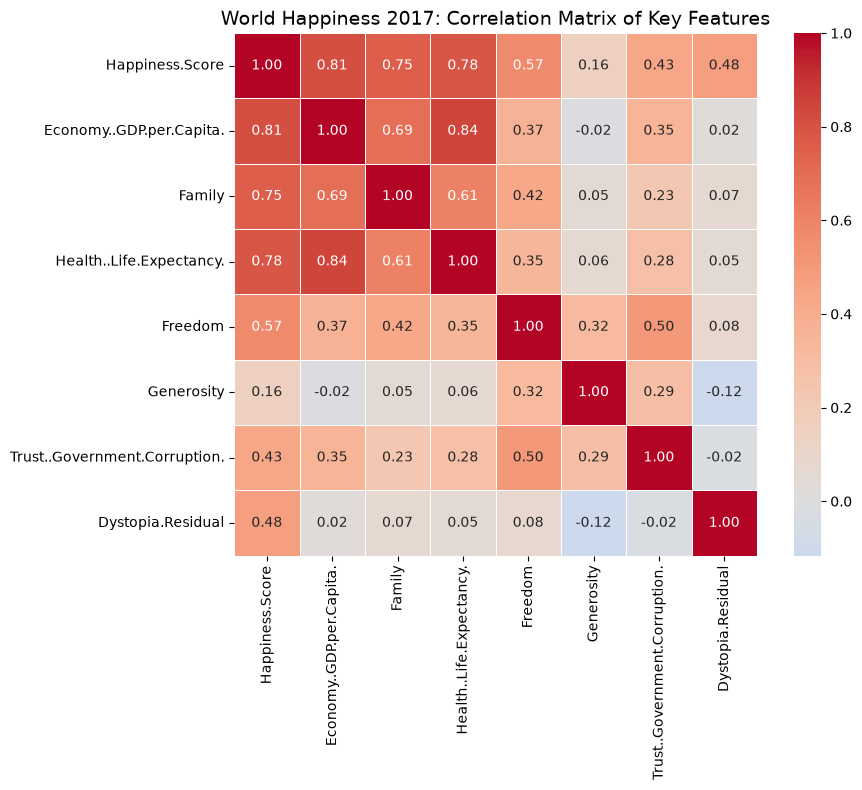

In [16]:


# 1. Auto-detect numeric columns
numeric_cols = happiness_df.select_dtypes(include=['number']).columns.tolist()

# 2. Drop useless columns SPECIFIC TO 2017 (Whiskers and Rank)
cols_to_exclude = [
    'Happiness.Rank', 'Happiness Rank', 
    'Whisker.high', 'Whisker.low',
    'Lower Confidence Interval', 'Upper Confidence Interval',
    'Lower confidence interval', 'Upper confidence interval',
    'Year'
]
clean_cols = [c for c in numeric_cols if c not in cols_to_exclude]

# 3. Calculate correlation matrix
corr = happiness_df[clean_cols].corr()

# 4. Plot the full square heatmap
fig, ax = plt.subplots(figsize=(10, 8))

sns.heatmap(
    corr, 
    annot=True,         # Show numbers inside the squares
    fmt=".2f",          # 2 decimal places
    cmap="coolwarm",    # Blue to Red colors
    center=0,           # White is exactly 0
    ax=ax, 
    square=True,        # Make the squares perfectly square
    linewidths=0.5      # Small lines between squares
)

# Update the title for 2017
ax.set_title("World Happiness 2017: Correlation Matrix of Key Features", fontsize=14)
plt.tight_layout()
plt.show()